# PPO - Acrobot: balancear el doble pendulo en el equilibrio inestable

Mismo problema que el notebook `DQN_acrobot_balance`, pero resuelto con **PPO** (Proximal Policy Optimization, version CleanRL con acciones discretas).

Entorno (identico al de DQN):

- **Acciones**: 7 torques discretos equiespaciados entre `-max_torque` y `+max_torque`.
- **Recompensa**: depende de la altura de la punta, `h = -cos(theta1) - cos(theta1 + theta2)` (`h = -2` colgando, `h = +2` erguido), mas un bonus de balanceo cerca de la vertical y con poca velocidad.
- **Sin terminacion**: el episodio solo termina por limite de tiempo (truncation).
- **Observacion**: `[cos th1, sin th1, cos th2, sin th2, w1/(4pi), w2/(9pi)]`.
- **Inicio aleatorio (solo entrenamiento)** con cierta probabilidad.

Diferencias de algoritmo respecto a DQN:

- PPO es *on-policy*: no hay replay buffer ni red objetivo ni epsilon-greedy. Se recolectan rollouts de `num_steps` pasos en `num_envs` entornos en paralelo y se actualiza la politica varias epocas con el objetivo *clipped*.
- Red **actor-critico**: el actor devuelve logits sobre las 7 acciones y el critico estima `V(s)`.
- Ventajas con **GAE(lambda)**.
- Como el entorno solo trunca por tiempo, en cada truncation se hace *bootstrap* con `V(final_obs)` en vez de tratarlo como un estado terminal.

---

## Cambios de esta version (diagnostico sobre la corrida anterior)

La corrida original se quedaba en ~345 de retorno (azar: ~245) con entropia ~1.85 (maximo posible: ln 7 = 1.95), es decir, una politica casi uniforme, y el modelo greedy se estabilizaba con la punta a altura h ~ 0 (brazos horizontales), nunca erguido. Causas y correcciones:

1. **Critico bloqueado por `clip_vloss` + retornos grandes.** El valor objetivo llegaba a ~100-200 y el clipping limita cada actualizacion del critico a +-0.2 -> varianza explicada oscilando entre -2.5 y 0.5. Ahora: `clip_vloss=False` y recompensas escaladas (`reward_scale`).
2. **`ent_coef=0.05` demasiado alto**: mantiene la politica casi aleatoria. Ahora 0.01.
3. **Recompensa lineal en la altura** -> optimo local facil en h ~ 0 (~0.5 por paso). Ahora la altura entra al cuadrado, y el bonus de balanceo pesa mas y usa una gaussiana de la velocidad.
4. **Inicios aleatorios cerca de la vertical** (curriculum) para que el agente vea estados de balanceo desde el principio.
5. **Torques no uniformes** (mas finos cerca de 0) para poder corregir con precision arriba.
6. **Horizonte y entrenamiento**: `gamma=0.995`, rollouts de 512 pasos, 2M pasos.
7. **Evaluacion periodica durante el entrenamiento** y guardado del **mejor modelo** (el retorno ya no es comparable con la version anterior; se miran altura y fraccion balanceada).


In [95]:
import os
import random
import time

from dataclasses import dataclass

import gymnasium as gym
from gymnasium import spaces
from gymnasium.envs.classic_control.acrobot import AcrobotEnv, wrap, bound

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions.categorical import Categorical

from torch.utils.tensorboard import SummaryWriter

import matplotlib.pyplot as plt

In [96]:
# HIPERPARAMETROS
@dataclass
class Args:
    exp_name: str = 'ppo_acrobot_balance_v5'
    seed: int = 1
    torch_deterministic: bool = True
    cuda: bool = False

    # Entorno
    env_id: str = 'AcrobotBalance'
    n_torques: int = 9
    max_torque: float = 1.8          # un poco menos de fuerza bruta
    torque_power: float = 2.5        # más resolución cerca de 0
    dt: float = 0.05
    rk4_substeps: int = 2
    max_episode_steps: int = 1200
    random_init_prob: float = 0.35   # menos caos al inicio
    near_upright_prob: float = 0.80  # la mayoría de los random arrancan arriba

    # Recompensa
    height_power: float = 3.0
    balance_weight: float = 12.0     # mucho más incentivo a estabilizar
    speed_pen_height: float = 1.60
    speed_pen_weight: float = 2.5
    reward_scale: float = 0.08       # un poco más bajo para estabilizar critic

    # PPO
    total_timesteps: int = 2_500_000
    learning_rate: float = 2.5e-4
    num_envs: int = 8
    num_steps: int = 1280            # rollouts más largos
    anneal_lr: bool = True
    gamma: float = 0.998
    gae_lambda: float = 0.95
    num_minibatches: int = 16
    update_epochs: int = 10
    norm_adv: bool = True
    clip_coef: float = 0.2
    clip_vloss: bool = False
    ent_coef_start: float = 0.012
    ent_coef_end: float = 0.001
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    target_kl: float = 0.015

    # Evaluación
    eval_every: int = 12
    eval_episodes: int = 6


args = Args()

args.batch_size = args.num_envs * args.num_steps
args.minibatch_size = args.batch_size // args.num_minibatches
args.num_iterations = args.total_timesteps // args.batch_size
args.max_step_reward = 1.0 + args.balance_weight
print('batch_size:', args.batch_size, '| minibatch_size:', args.minibatch_size, '| iteraciones:', args.num_iterations)

batch_size: 10240 | minibatch_size: 640 | iteraciones: 244


In [97]:
# rk4 propio compatible con NumPy 2
def rk4(derivs, y0, t):
    y = np.asarray(y0, dtype=np.float64)
    for i in range(len(t) - 1):
        dt = t[i + 1] - t[i]
        dt2 = dt / 2.0
        k1 = np.asarray(derivs(y))
        k2 = np.asarray(derivs(y + dt2 * k1))
        k3 = np.asarray(derivs(y + dt2 * k2))
        k4 = np.asarray(derivs(y + dt * k3))
        y = y + dt / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y[:4]


class AcrobotBalanceEnv(AcrobotEnv):

    def __init__(self, n_torques=9, max_torque=1.8, torque_power=2.5, dt=0.05, rk4_substeps=2,
                 random_init_prob=0.0, near_upright_prob=0.8, height_power=3.0,
                 balance_weight=12.0, speed_pen_height=1.6, speed_pen_weight=2.5, render_mode=None):
        super().__init__(render_mode=render_mode)

        self.dt = dt
        self.rk4_substeps = rk4_substeps
        self.max_torque = max_torque

        # Torques discretos simétricos con alta resolución cerca de 0
        u = np.linspace(-1.0, 1.0, n_torques)
        self.AVAIL_TORQUE = max_torque * np.sign(u) * np.abs(u) ** torque_power
        self.action_space = spaces.Discrete(n_torques)

        # Observación 8D: cos/sin de cada ángulo + cos/sin del ángulo de la punta + tanh(velocidades)
        self.observation_space = spaces.Box(
            low=-1.0, high=1.0, shape=(8,), dtype=np.float32
        )

        self.random_init_prob = random_init_prob
        self.near_upright_prob = near_upright_prob
        self.height_power = height_power
        self.balance_weight = balance_weight
        self.speed_pen_height = speed_pen_height
        self.speed_pen_weight = speed_pen_weight

    def _get_ob(self):
        s = self.state
        th_sum = s[0] + s[1]
        return np.array(
            [
                np.cos(s[0]), np.sin(s[0]),
                np.cos(s[1]), np.sin(s[1]),
                np.cos(th_sum), np.sin(th_sum),
                np.tanh(s[2] / 2.0),
                np.tanh(s[3] / 3.0),
            ],
            dtype=np.float32,
        )

    @staticmethod
    def tip_height(s):
        # -2 = colgando, +2 = vertical hacia arriba
        return -np.cos(s[0]) - np.cos(s[0] + s[1])

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed, options=options)

        if self.np_random.random() < self.random_init_prob:
            if self.np_random.random() < self.near_upright_prob:
                # Cono cerca de la vertical con velocidades moderadas
                th1 = wrap(np.pi + self.np_random.uniform(-0.30, 0.30), -np.pi, np.pi)
                th2 = self.np_random.uniform(-0.30, 0.30)
                w = self.np_random.uniform(-0.6, 0.6, size=2)
                self.state = np.array([th1, th2, w[0], w[1]], dtype=np.float32)
            else:
                self.state = self.np_random.uniform(
                    low=[-np.pi, -np.pi, -1.2, -1.2],
                    high=[np.pi, np.pi, 1.2, 1.2],
                ).astype(np.float32)

        return self._get_ob(), {}

    def step(self, a):
        s = self.state
        assert s is not None, 'Llamar a reset() antes de step()'

        torque = self.AVAIL_TORQUE[a]

        if self.torque_noise_max > 0:
            torque += self.np_random.uniform(-self.torque_noise_max, self.torque_noise_max)

        # Integración RK4
        s_augmented = np.append(s, torque)
        t_grid = np.linspace(0.0, self.dt, self.rk4_substeps + 1)
        ns = rk4(self._dsdt, s_augmented, t_grid)

        ns[0] = wrap(ns[0], -np.pi, np.pi)
        ns[1] = wrap(ns[1], -np.pi, np.pi)
        ns[2] = bound(ns[2], -self.MAX_VEL_1, self.MAX_VEL_1)
        ns[3] = bound(ns[3], -self.MAX_VEL_2, self.MAX_VEL_2)
        self.state = ns

        # ---------- Recompensa v5 ----------
        h = self.tip_height(ns)
        speed = abs(ns[2]) + abs(ns[3])

        # 1. Altura cúbica → empuja el swing-up
        height_term = ((h + 2.0) / 4.0) ** self.height_power

        # 2. Bonus de balanceo fuerte (gate suave desde h≈1.3)
        gate_bal = np.clip((h - 1.30) / 0.70, 0.0, 1.0) ** 1.2
        balance_term = gate_bal * np.exp(-(speed / 1.5) ** 2)

        # 3. Bonus extra por estar casi quieto muy cerca de la vertical
        still_bonus = 0.0
        if h > 1.75:
            still_bonus = 1.5 * np.exp(-(speed / 0.9) ** 2) * ((h - 1.75) / 0.25)

        # 4. Penalización de velocidad agresiva solo arriba
        if h > self.speed_pen_height:
            high_zone = np.clip((h - self.speed_pen_height) / (2.0 - self.speed_pen_height), 0.0, 1.0)
            speed_pen = self.speed_pen_weight * high_zone * np.tanh(speed / 2.5)
        else:
            speed_pen = 0.0

        # 5. Penalización suave de esfuerzo solo en zona de equilibrio
        effort_pen = 0.04 * gate_bal * ((torque / self.max_torque) ** 2)

        reward = float(
            height_term
            + self.balance_weight * balance_term
            + still_bonus
            - speed_pen
            - effort_pen
        )

        balanced = bool(h > 1.85 and speed < 0.7)
        info = {'height': float(h), 'balanced': balanced, 'speed': float(speed)}

        if self.render_mode == 'human':
            self.render()

        return self._get_ob(), reward, False, False, info

In [98]:
def make_env(seed, idx, capture_video, run_name, random_init_prob=0.0):

    def thunk():

        render_mode = 'rgb_array' if (capture_video and idx == 0) else None

        env = AcrobotBalanceEnv(
                    n_torques=args.n_torques,
                    max_torque=args.max_torque,
                    torque_power=args.torque_power,
                    dt=args.dt,
                    rk4_substeps=args.rk4_substeps,
                    random_init_prob=random_init_prob,
                    near_upright_prob=args.near_upright_prob,
                    height_power=args.height_power,
                    balance_weight=args.balance_weight,
                    speed_pen_height=args.speed_pen_height,
                    speed_pen_weight=args.speed_pen_weight,
                    render_mode=render_mode,
                )
        env = gym.wrappers.TimeLimit(env, max_episode_steps=args.max_episode_steps)

        if render_mode is not None:
            env = gym.wrappers.RecordVideo(env, f'videos/{run_name}')

        env = gym.wrappers.RecordEpisodeStatistics(env)
        env.action_space.seed(seed)

        return env

    return thunk

In [99]:
def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer


class Agent(nn.Module):

    def __init__(self, envs):
        super().__init__()

        obs_dim = int(np.array(envs.single_observation_space.shape).prod())
        n_actions = int(envs.single_action_space.n)

        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 128)),
            nn.Tanh(),
            layer_init(nn.Linear(128, 128)),
            nn.Tanh(),
            layer_init(nn.Linear(128, 1), std=1.0),
        )

        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 128)),
            nn.Tanh(),
            layer_init(nn.Linear(128, 128)),
            nn.Tanh(),
            layer_init(nn.Linear(128, n_actions), std=0.01),
        )

    def get_value(self, x):
        return self.critic(x)

    def get_action_and_value(self, x, action=None):
        logits = self.actor(x)
        probs = Categorical(logits=logits)

        if action is None:
            action = probs.sample()

        return action, probs.log_prob(action), probs.entropy(), self.critic(x)

In [100]:
def make_eval_env(random_init_prob=0.0, render_mode=None):
    env = AcrobotBalanceEnv(
        n_torques=args.n_torques,
        max_torque=args.max_torque,
        torque_power=args.torque_power,
        dt=args.dt,
        rk4_substeps=args.rk4_substeps,
        random_init_prob=random_init_prob,
        near_upright_prob=args.near_upright_prob,
        height_power=args.height_power,
        balance_weight=args.balance_weight,
        speed_pen_height=args.speed_pen_height,
        speed_pen_weight=args.speed_pen_weight,
        render_mode=render_mode,
    )
    return gym.wrappers.TimeLimit(env, max_episode_steps=args.max_episode_steps)


def evaluate(model, n_episodes=20, random_init_prob=0.0, seed=42, verbose=True):
    env = make_eval_env(random_init_prob)
    results = {'returns': [], 'final_height': [], 'max_height': [], 'balanced_frac': []}

    for ep in range(n_episodes):
        obs_ep, _ = env.reset(seed=seed + ep)
        done = False
        total = 0.0
        heights = []
        balanced = []

        while not done:
            with torch.no_grad():
                logits = model.actor(torch.Tensor(obs_ep).unsqueeze(0).to(device))
            action = torch.argmax(logits, dim=1).item()

            obs_ep, reward, terminated, truncated, info = env.step(action)
            total += reward
            heights.append(info['height'])
            balanced.append(info['balanced'])
            done = terminated or truncated

        results['returns'].append(total)
        results['final_height'].append(np.mean(heights[-200:]))
        results['max_height'].append(np.max(heights))
        results['balanced_frac'].append(np.mean(balanced))

        if verbose:
            print(
                f'Episodio {ep + 1}: recompensa = {total:.1f}, '
                f'altura final media = {results["final_height"][-1]:.2f}, '
                f'altura maxima = {results["max_height"][-1]:.2f}, '
                f'balanceado = {100 * results["balanced_frac"][-1]:.0f}% del episodio'
            )

    env.close()
    return results

In [101]:
run_name = f'{args.env_id}__{args.exp_name}__{args.seed}__{int(time.time())}'
os.makedirs('runs', exist_ok=True)
writer = SummaryWriter(f'runs/{run_name}')

random.seed(args.seed)
np.random.seed(args.seed)
torch.manual_seed(args.seed)
torch.backends.cudnn.deterministic = args.torch_deterministic

device = torch.device('cuda' if torch.cuda.is_available() and args.cuda else 'cpu')
print('Dispositivo seleccionado:', device)

envs = gym.vector.SyncVectorEnv(
    [
        make_env(
            args.seed + i,
            i,
            False,
            run_name,
            random_init_prob=args.random_init_prob
        )
        for i in range(args.num_envs)
    ]
)

assert isinstance(envs.single_action_space, gym.spaces.Discrete)

print('Observaciones:', envs.single_observation_space.shape)
print('Acciones:', envs.single_action_space.n)
print('Torques:', np.round(envs.envs[0].unwrapped.AVAIL_TORQUE, 3))

agent = Agent(envs).to(device)
best_agent = Agent(envs).to(device)
best_state = None
best_score = -np.inf
eval_history = []

optimizer = optim.Adam(agent.parameters(), lr=args.learning_rate, eps=1e-5)

obs = torch.zeros((args.num_steps, args.num_envs) + envs.single_observation_space.shape).to(device)
actions = torch.zeros((args.num_steps, args.num_envs) + envs.single_action_space.shape).to(device)
logprobs = torch.zeros((args.num_steps, args.num_envs)).to(device)
rewards = torch.zeros((args.num_steps, args.num_envs)).to(device)
dones = torch.zeros((args.num_steps, args.num_envs)).to(device)
values = torch.zeros((args.num_steps, args.num_envs)).to(device)

global_step = 0
start_time = time.time()
episodic_returns = []

next_obs, _ = envs.reset(seed=args.seed)
next_obs = torch.Tensor(next_obs).to(device)
next_done = torch.zeros(args.num_envs).to(device)

print('Inicializacion completada.')

Dispositivo seleccionado: cpu
Observaciones: (8,)
Acciones: 9
Torques: [-1.8   -0.877 -0.318 -0.056  0.     0.056  0.318  0.877  1.8  ]
Inicializacion completada.


In [102]:
for iteration in range(1, args.num_iterations + 1):

    frac = 1.0 - (iteration - 1.0) / args.num_iterations
    if args.anneal_lr:
        optimizer.param_groups[0]['lr'] = frac * args.learning_rate

    current_ent_coef = args.ent_coef_end + frac * (args.ent_coef_start - args.ent_coef_end)

    for step in range(args.num_steps):

        global_step += args.num_envs

        obs[step] = next_obs
        dones[step] = next_done

        with torch.no_grad():
            action, logprob, _, value = agent.get_action_and_value(next_obs)
            values[step] = value.flatten()

        actions[step] = action
        logprobs[step] = logprob

        next_obs_np, reward, terminations, truncations, infos = envs.step(action.cpu().numpy())

        next_done_np = np.logical_or(terminations, truncations)
        rewards[step] = torch.tensor(reward, dtype=torch.float32).to(device) * args.reward_scale

        # Bootstrap en truncations (el entorno no termina por éxito)
        for idx, trunc in enumerate(truncations):
            if trunc:
                final_obs = torch.Tensor(infos['final_observation'][idx]).unsqueeze(0).to(device)
                with torch.no_grad():
                    final_value = agent.get_value(final_obs).item()
                rewards[step][idx] += args.gamma * final_value

        next_obs = torch.Tensor(next_obs_np).to(device)
        next_done = torch.Tensor(next_done_np.astype(np.float32)).to(device)

        if 'final_info' in infos:
            for info in infos['final_info']:
                if info and 'episode' in info:
                    episodic_returns.append(info['episode']['r'])
                    writer.add_scalar('charts/episodic_return', info['episode']['r'], global_step)
                    writer.add_scalar('charts/episodic_length', info['episode']['l'], global_step)
                    if len(episodic_returns) % 10 == 0:
                        print(
                            f'global_step={global_step}, episodios={len(episodic_returns)}, '
                            f'retorno (ult. 10)={np.mean(episodic_returns[-10:]):.1f}'
                        )

    # --- GAE ---
    with torch.no_grad():
        next_value = agent.get_value(next_obs).reshape(1, -1)
        advantages = torch.zeros_like(rewards).to(device)
        lastgaelam = 0
        for t in reversed(range(args.num_steps)):
            if t == args.num_steps - 1:
                nextnonterminal = 1.0 - next_done
                nextvalues = next_value
            else:
                nextnonterminal = 1.0 - dones[t + 1]
                nextvalues = values[t + 1]
            delta = rewards[t] + args.gamma * nextvalues * nextnonterminal - values[t]
            advantages[t] = lastgaelam = delta + args.gamma * args.gae_lambda * nextnonterminal * lastgaelam
        returns = advantages + values

    # --- Flatten ---
    b_obs = obs.reshape((-1,) + envs.single_observation_space.shape)
    b_logprobs = logprobs.reshape(-1)
    b_actions = actions.reshape((-1,) + envs.single_action_space.shape)
    b_advantages = advantages.reshape(-1)
    b_returns = returns.reshape(-1)
    b_values = values.reshape(-1)

    # --- Update ---
    b_inds = np.arange(args.batch_size)
    clipfracs = []
    for epoch in range(args.update_epochs):
        np.random.shuffle(b_inds)
        for start in range(0, args.batch_size, args.minibatch_size):
            end = start + args.minibatch_size
            mb_inds = b_inds[start:end]

            _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                b_obs[mb_inds], b_actions.long()[mb_inds]
            )
            logratio = newlogprob - b_logprobs[mb_inds]
            ratio = logratio.exp()

            with torch.no_grad():
                old_approx_kl = (-logratio).mean()
                approx_kl = ((ratio - 1) - logratio).mean()
                clipfracs += [((ratio - 1.0).abs() > args.clip_coef).float().mean().item()]

            mb_advantages = b_advantages[mb_inds]
            if args.norm_adv:
                mb_advantages = (mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)

            # Policy loss
            pg_loss1 = -mb_advantages * ratio
            pg_loss2 = -mb_advantages * torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
            pg_loss = torch.max(pg_loss1, pg_loss2).mean()

            # Value loss
            newvalue = newvalue.view(-1)
            if args.clip_vloss:
                v_loss_unclipped = (newvalue - b_returns[mb_inds]) ** 2
                v_clipped = b_values[mb_inds] + torch.clamp(
                    newvalue - b_values[mb_inds], -args.clip_coef, args.clip_coef
                )
                v_loss_clipped = (v_clipped - b_returns[mb_inds]) ** 2
                v_loss_max = torch.max(v_loss_unclipped, v_loss_clipped)
                v_loss = 0.5 * v_loss_max.mean()
            else:
                v_loss = 0.5 * ((newvalue - b_returns[mb_inds]) ** 2).mean()

            entropy_loss = entropy.mean()
            loss = pg_loss - current_ent_coef * entropy_loss + v_loss * args.vf_coef

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), args.max_grad_norm)
            optimizer.step()

        if args.target_kl is not None and approx_kl > args.target_kl:
            break

    y_pred, y_true = b_values.cpu().numpy(), b_returns.cpu().numpy()
    var_y = np.var(y_true)
    explained_var = np.nan if var_y == 0 else 1 - np.var(y_true - y_pred) / var_y

    # Logging
    writer.add_scalar('charts/learning_rate', optimizer.param_groups[0]['lr'], global_step)
    writer.add_scalar('losses/value_loss', v_loss.item(), global_step)
    writer.add_scalar('losses/policy_loss', pg_loss.item(), global_step)
    writer.add_scalar('losses/entropy', entropy_loss.item(), global_step)
    writer.add_scalar('losses/old_approx_kl', old_approx_kl.item(), global_step)
    writer.add_scalar('losses/approx_kl', approx_kl.item(), global_step)
    writer.add_scalar('losses/clipfrac', np.mean(clipfracs), global_step)
    writer.add_scalar('losses/explained_variance', explained_var, global_step)
    writer.add_scalar('charts/SPS', int(global_step / (time.time() - start_time)), global_step)
    writer.add_scalar('charts/ent_coef', current_ent_coef, global_step)

    if iteration % 10 == 0:
        print(
            f'iteracion {iteration}/{args.num_iterations} | '
            f'SPS={int(global_step / (time.time() - start_time))} | '
            f'entropia={entropy_loss.item():.3f} | '
            f'kl={approx_kl.item():.4f} | '
            f'var. explicada={explained_var:.2f}'
        )

    # --- Evaluación periódica y best model ---
    if iteration % args.eval_every == 0 or iteration == args.num_iterations:
        eval_res = evaluate(agent, n_episodes=args.eval_episodes, random_init_prob=0.0, verbose=False)
        mean_final_h = np.mean(eval_res['final_height'])
        mean_bal = np.mean(eval_res['balanced_frac'])
        mean_max_h = np.mean(eval_res['max_height'])

        # Score orientado a estabilización (no solo retorno)
        score = 0.55 * mean_final_h + 0.45 * mean_bal * 2.0   # balanceado tiene peso alto

        eval_history.append({
            'iteration': iteration,
            'final_height': mean_final_h,
            'balanced_frac': mean_bal,
            'max_height': mean_max_h,
            'score': score,
        })

        writer.add_scalar('eval/final_height', mean_final_h, global_step)
        writer.add_scalar('eval/balanced_frac', mean_bal, global_step)
        writer.add_scalar('eval/max_height', mean_max_h, global_step)
        writer.add_scalar('eval/score', score, global_step)

        if score > best_score:
            best_score = score
            best_state = {k: v.cpu().clone() for k, v in agent.state_dict().items()}
            best_agent.load_state_dict(best_state)

        print(
            f'   [eval] altura final={mean_final_h:.2f} | '
            f'altura max={mean_max_h:.2f} | '
            f'balanceado={100*mean_bal:.0f}% | '
            f'mejor score={best_score:.3f}'
        )

print('Entrenamiento finalizado.')

global_step=19200, episodios=10, retorno (ult. 10)=139.4
global_step=28800, episodios=20, retorno (ult. 10)=79.9
global_step=38400, episodios=30, retorno (ult. 10)=86.5
global_step=48000, episodios=40, retorno (ult. 10)=196.4
global_step=67200, episodios=50, retorno (ult. 10)=118.6
global_step=76800, episodios=60, retorno (ult. 10)=94.8
global_step=86400, episodios=70, retorno (ult. 10)=102.8
global_step=96000, episodios=80, retorno (ult. 10)=99.5
iteracion 10/244 | SPS=1966 | entropia=2.137 | kl=0.0050 | var. explicada=0.86
global_step=115200, episodios=90, retorno (ult. 10)=107.6
   [eval] altura final=-1.99 | altura max=-1.98 | balanceado=0% | mejor score=-1.096
global_step=124800, episodios=100, retorno (ult. 10)=216.6
global_step=134400, episodios=110, retorno (ult. 10)=72.5
global_step=144000, episodios=120, retorno (ult. 10)=92.2
global_step=163200, episodios=130, retorno (ult. 10)=95.6
global_step=172800, episodios=140, retorno (ult. 10)=97.6
global_step=182400, episodios=150, 

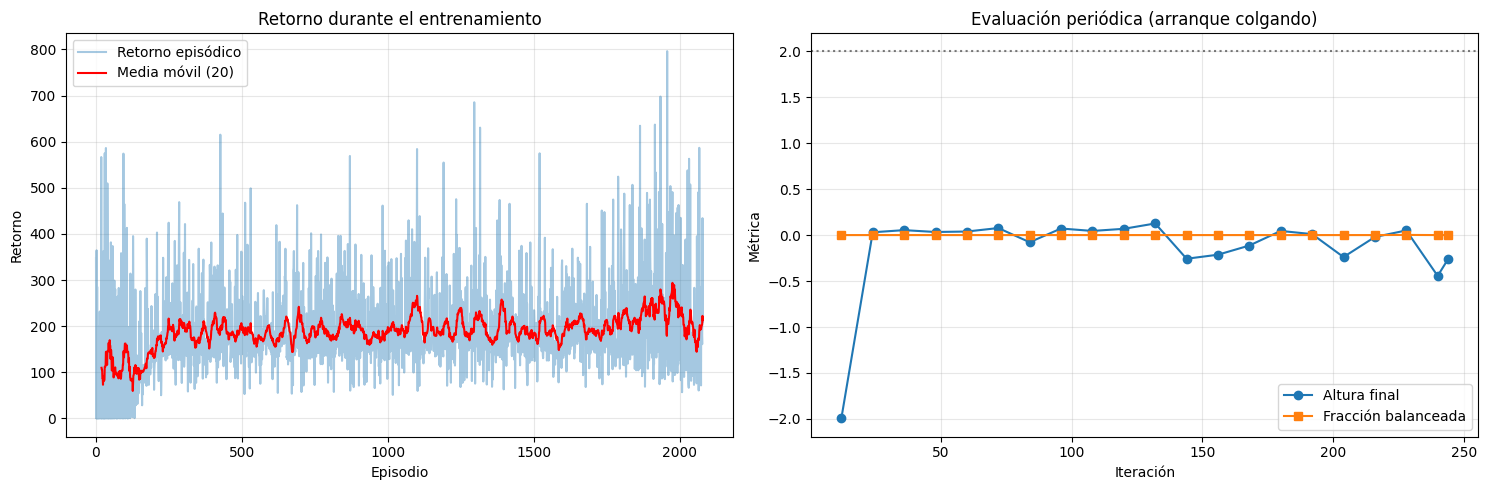

In [105]:
# Visualizar aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Aseguramos que sea un array 1D de floats
returns_flat = np.array(episodic_returns, dtype=np.float64).ravel()

axes[0].plot(returns_flat, alpha=0.4, label='Retorno episódico')
if len(returns_flat) > 20:
    window = 20
    smooth = np.convolve(returns_flat, np.ones(window)/window, mode='valid')
    axes[0].plot(range(window-1, len(returns_flat)), smooth, color='red', label=f'Media móvil ({window})')
axes[0].set_xlabel('Episodio')
axes[0].set_ylabel('Retorno')
axes[0].set_title('Retorno durante el entrenamiento')
axes[0].legend()
axes[0].grid(alpha=0.3)

if eval_history:
    iters = [e['iteration'] for e in eval_history]
    axes[1].plot(iters, [e['final_height'] for e in eval_history], marker='o', label='Altura final')
    axes[1].plot(iters, [e['balanced_frac'] for e in eval_history], marker='s', label='Fracción balanceada')
    axes[1].axhline(2.0, color='black', linestyle=':', alpha=0.5)
    axes[1].set_xlabel('Iteración')
    axes[1].set_ylabel('Métrica')
    axes[1].set_title('Evaluación periódica (arranque colgando)')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [106]:
model_path = f'runs/{run_name}/ppo_final.pt'
os.makedirs(os.path.dirname(model_path), exist_ok=True)
torch.save(agent.state_dict(), model_path)
print(f'Modelo final guardado en {model_path}')

if best_state is not None:
    best_path = f'runs/{run_name}/ppo_best.pt'
    torch.save(best_state, best_path)
    print(f'Mejor modelo (score={best_score:.3f}) guardado en {best_path}')

Modelo final guardado en runs/AcrobotBalance__ppo_acrobot_balance_v5__1__1794772804/ppo_final.pt
Mejor modelo (score=0.069) guardado en runs/AcrobotBalance__ppo_acrobot_balance_v5__1__1794772804/ppo_best.pt


In [ ]:
# Cerrar entorno
# IMPORTANTE: primero guardar los parametros
#envs.close()
#writer.close()

In [107]:
# Cargar parametros guardados
""""

# Ruta del archivo guardado (ajustarla a tu corrida)
model_path = 'runs/RUN_NAME/ppo_model.pth'

device = torch.device('cpu')

# Agent necesita un entorno vectorizado para leer los espacios de observacion y accion
tmp_envs = gym.vector.SyncVectorEnv([make_env(0, 0, False, 'eval')])

loaded_model = Agent(tmp_envs).to(device)
loaded_model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
loaded_model.eval()

tmp_envs.close()
print('Modelo cargado correctamente.')
""""

SyntaxError: unterminated string literal (detected at line 18) (2527802601.py, line 18)

In [108]:
print('=== Modelo final ===')
eval_results = evaluate(agent, n_episodes=15, random_init_prob=0.0, seed=42, verbose=True)

print('\n=== Mejor modelo (según score de estabilización) ===')
eval_best = evaluate(best_agent, n_episodes=15, random_init_prob=0.0, seed=42, verbose=True)

=== Modelo final ===
Episodio 1: recompensa = 130.8, altura final media = -0.27, altura maxima = 1.45, balanceado = 0% del episodio
Episodio 2: recompensa = 176.8, altura final media = -0.12, altura maxima = 1.99, balanceado = 0% del episodio
Episodio 3: recompensa = 104.2, altura final media = -0.47, altura maxima = 1.80, balanceado = 0% del episodio
Episodio 4: recompensa = 168.5, altura final media = -0.43, altura maxima = 1.88, balanceado = 0% del episodio
Episodio 5: recompensa = 111.4, altura final media = -0.55, altura maxima = 1.41, balanceado = 0% del episodio
Episodio 6: recompensa = 321.4, altura final media = 0.27, altura maxima = 1.99, balanceado = 0% del episodio
Episodio 7: recompensa = 499.5, altura final media = 0.26, altura maxima = 1.97, balanceado = 1% del episodio
Episodio 8: recompensa = 261.6, altura final media = 0.11, altura maxima = 1.72, balanceado = 0% del episodio
Episodio 9: recompensa = 214.7, altura final media = 0.20, altura maxima = 2.00, balanceado = 


--- Resumen (mejor modelo) ---
Retorno promedio: 147.7 (máximo posible ~ 15600)
Desvío:           51.2
Altura final media: 0.02 (máximo = 2)
Altura máxima alcanzada (media): 1.89
Tiempo balanceado:  0.0%


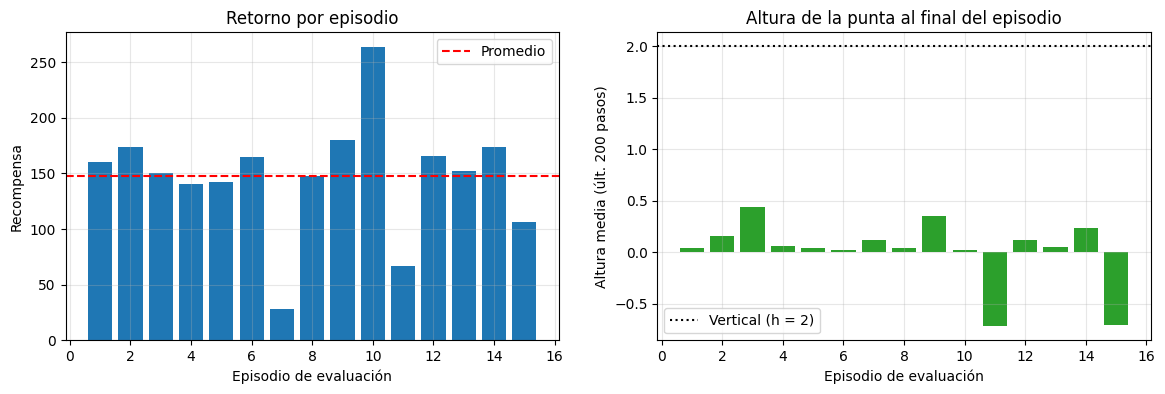

In [109]:
eval_returns = eval_best['returns']   # usamos el mejor modelo

print('\n--- Resumen (mejor modelo) ---')
print(f'Retorno promedio: {np.mean(eval_returns):.1f} (máximo posible ~ {args.max_step_reward * args.max_episode_steps:.0f})')
print(f'Desvío:           {np.std(eval_returns):.1f}')
print(f'Altura final media: {np.mean(eval_best["final_height"]):.2f} (máximo = 2)')
print(f'Altura máxima alcanzada (media): {np.mean(eval_best["max_height"]):.2f}')
print(f'Tiempo balanceado:  {100 * np.mean(eval_best["balanced_frac"]):.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(range(1, len(eval_returns) + 1), eval_returns)
axes[0].axhline(np.mean(eval_returns), color='red', linestyle='--', label='Promedio')
axes[0].set_xlabel('Episodio de evaluación')
axes[0].set_ylabel('Recompensa')
axes[0].set_title('Retorno por episodio')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(range(1, len(eval_returns) + 1), eval_best['final_height'], color='tab:green')
axes[1].axhline(2.0, color='black', linestyle=':', label='Vertical (h = 2)')
axes[1].set_xlabel('Episodio de evaluación')
axes[1].set_ylabel('Altura media (últ. 200 pasos)')
axes[1].set_title('Altura de la punta al final del episodio')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.show()

In [110]:
video_env = make_eval_env(render_mode='rgb_array')
video_env = gym.wrappers.RecordVideo(
    video_env,
    video_folder='videos_eval',
    episode_trigger=lambda ep: True,
)

for ep in range(1):
    obs_ep, _ = video_env.reset(seed=100 + ep)
    done = False
    while not done:
        with torch.no_grad():
            logits = best_agent.actor(torch.Tensor(obs_ep).unsqueeze(0).to(device))
        action = torch.argmax(logits, dim=1).item()
        obs_ep, reward, terminated, truncated, _ = video_env.step(action)
        done = terminated or truncated

video_env.close()
print("Videos guardados en la carpeta 'videos_eval'.")

/home/francisco/apRef/.venv/lib/python3.10/site-packages/gymnasium/wrappers/record_video.py:94: UserWarning: WARN: Overwriting existing videos at /home/francisco/apRef/ACROBOT PPO/videos_eval folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


MoviePy - Building video /home/francisco/apRef/ACROBOT PPO/videos_eval/rl-video-episode-0.mp4.
MoviePy - Writing video /home/francisco/apRef/ACROBOT PPO/videos_eval/rl-video-episode-0.mp4



MoviePy - Done !
MoviePy - video ready /home/francisco/apRef/ACROBOT PPO/videos_eval/rl-video-episode-0.mp4
Videos guardados en la carpeta 'videos_eval'.
